In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

customers = pd.read_csv("customers.csv")

customers.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


In [ ]:
'''
rows num = 99457
features num = 10
missing values = 0
price may have an outlier 
'''

'''  invoice_no
id nums isn't serial and there is a lot of missing ids in the middle

'''

''' customer_id
no customer repeated the same hotel or tried another
'''

''' gender

categorical
2 categories 
Female    59482
Male      39975

'''

''' age
range (18, 69)
'''

''' category
8 categories 
highest = 34487
lowest = 4981
'''

''' price 

may have an outlier
'''



# General

In [14]:
customers.shape

(99457, 10)

In [12]:
customers.isnull().sum()

invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64

In [30]:
customers.describe()

,age,quantity,price
count,99457.000000,99457.000000,99457.000000
mean,43.427089,3.003429,689.256321
std,14.990054,1.413025,941.184567
min,18.000000,1.000000,5.230000
25%,30.000000,2.000000,45.450000
50%,43.000000,3.000000,203.300000
75%,56.000000,4.000000,1200.320000
max,69.000000,5.000000,5250.000000


# invoice

In [24]:
customers.sort_values(["shopping_mall", "invoice_no"])

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
62085,I100082,C357288,Female,44,Souvenir,2,23.46,Cash,31/12/2021,Cevahir AVM
96331,I100098,C228071,Male,49,Clothing,5,1500.40,Cash,16/11/2021,Cevahir AVM
56117,I100108,C331773,Female,45,Books,4,60.60,Credit Card,6/8/2021,Cevahir AVM
66025,I100127,C708853,Male,38,Clothing,2,600.16,Debit Card,16/11/2021,Cevahir AVM
79795,I100198,C136883,Female,58,Cosmetics,5,203.30,Credit Card,18/07/2021,Cevahir AVM
...,...,...,...,...,...,...,...,...,...,...
92790,I998238,C261645,Female,26,Cosmetics,5,203.30,Cash,9/2/2022,Zorlu Center
5977,I999023,C248973,Male,21,Clothing,5,1500.40,Credit Card,11/3/2021,Zorlu Center
27028,I999077,C116360,Male,69,Toys,4,143.36,Credit Card,8/9/2022,Zorlu Center
66384,I999173,C168255,Female,45,Food & Beverage,2,10.46,Cash,2/8/2022,Zorlu Center


In [21]:
customers["invoice_date"] = pd.to_datetime(customers["invoice_date"], dayfirst=True)
customers.sort_values(["shopping_mall", "invoice_date"])


,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
30914,I312847,C535517,Male,60,Souvenir,1,11.73,Credit Card,2021-01-01,Cevahir AVM
67503,I983410,C118410,Male,61,Toys,4,143.36,Credit Card,2021-01-01,Cevahir AVM
81868,I202894,C191193,Male,21,Clothing,3,900.24,Cash,2021-01-01,Cevahir AVM
81971,I841258,C813957,Female,30,Food & Beverage,3,15.69,Cash,2021-01-01,Cevahir AVM
2783,I226368,C117004,Male,27,Toys,4,143.36,Cash,2021-01-02,Cevahir AVM
...,...,...,...,...,...,...,...,...,...,...
70975,I163665,C214893,Female,39,Food & Beverage,4,20.92,Cash,2023-03-07,Zorlu Center
2828,I167565,C759854,Female,38,Cosmetics,1,40.66,Cash,2023-03-08,Zorlu Center
12229,I158445,C297854,Male,62,Souvenir,4,46.92,Cash,2023-03-08,Zorlu Center
13719,I334563,C140873,Male,39,Clothing,2,600.16,Credit Card,2023-03-08,Zorlu Center


In [18]:
customers.sort_values("invoice_no")

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
98685,I100008,C199951,Male,65,Clothing,5,1500.40,Cash,10/7/2022,Emaar Square Mall
19495,I100014,C138893,Male,55,Cosmetics,5,203.30,Cash,18/06/2021,Viaport Outlet
6948,I100015,C132779,Female,35,Clothing,2,600.16,Debit Card,4/3/2021,Mall of Istanbul
94696,I100024,C244411,Female,67,Books,3,45.45,Credit Card,5/1/2023,Emaar Square Mall
36977,I100027,C150002,Female,19,Technology,4,4200.00,Cash,18/05/2022,Mall of Istanbul
...,...,...,...,...,...,...,...,...,...,...
39275,I999956,C925896,Male,69,Toys,4,143.36,Credit Card,16/08/2021,Metrocity
37020,I999959,C695980,Female,68,Clothing,4,1200.32,Credit Card,13/10/2021,Kanyon
21067,I999972,C195931,Male,63,Technology,2,2100.00,Debit Card,23/01/2021,Istinye Park
46474,I999973,C248542,Male,28,Technology,1,1050.00,Credit Card,11/1/2023,Mall of Istanbul


# Customers

In [82]:
customers["customer_id"].value_counts()
customers["customer_id"].unique()

array(['C241288', 'C111565', 'C266599', ..., 'C103292', 'C800631',
       'C273973'], shape=(99457,), dtype=object)

In [ ]:

customers.groupby("customer_id")["shopping_mall"].nunique().value_counts()
customers.groupby(["customer_id", "shopping_mall"]).size().value_counts()

1    99457
Name: count, dtype: int64

# Gender

In [29]:
customers["gender"].value_counts()


gender
Female    59482
Male      39975
Name: count, dtype: int64

# Age

In [31]:
customers["age"].min(), customers["age"].max()

(np.int64(18), np.int64(69))

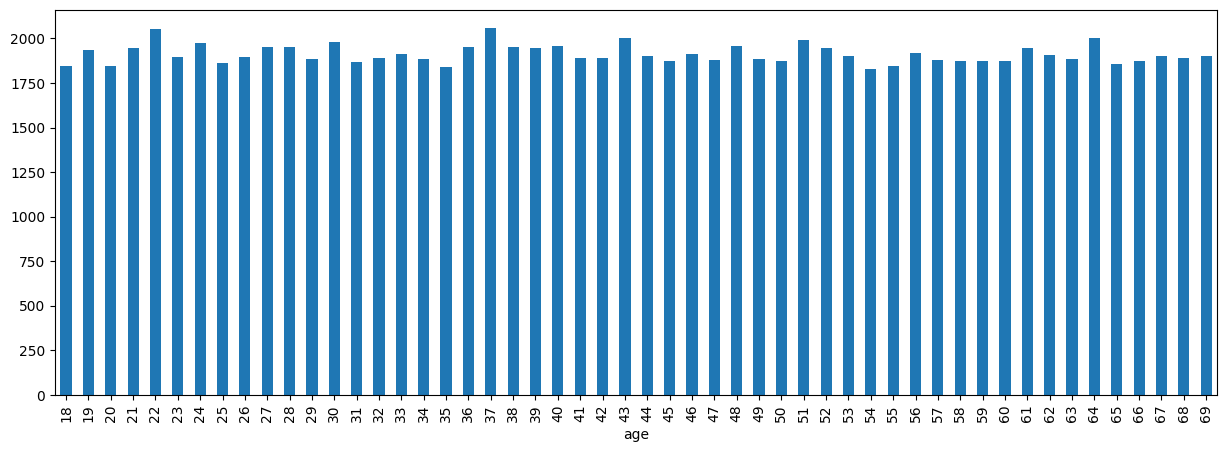

In [41]:
import matplotlib.pyplot as plt
customers["age"].value_counts().sort_index().plot(kind="bar", figsize=(15, 5))
plt.show()

# category

In [44]:
customers["category"].value_counts()

category
Clothing           34487
Cosmetics          15097
Food & Beverage    14776
Toys               10087
Shoes              10034
Souvenir            4999
Technology          4996
Books               4981
Name: count, dtype: int64

# quantity

In [45]:
customers["quantity"].min(), customers["quantity"].max()

(np.int64(1), np.int64(5))

# price

In [56]:
customers["price"].min(), customers["price"].max()

(np.float64(5.23), np.float64(5250.0))

<Axes: ylabel='Frequency'>

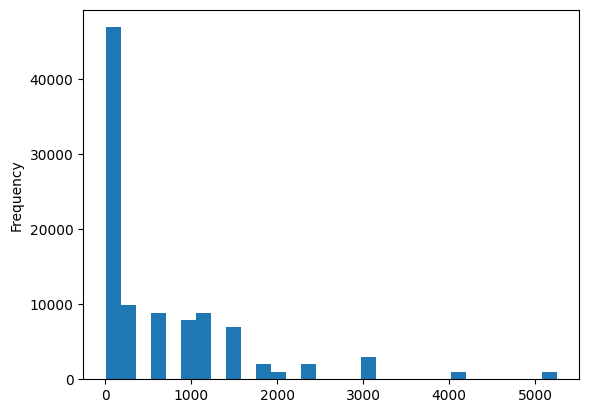

In [55]:
customers["price"].plot(kind="hist", bins=30)

# payment methods

In [61]:
customers["payment_method"].value_counts()

payment_method
Cash           44447
Credit Card    34931
Debit Card     20079
Name: count, dtype: int64

<Axes: title={'center': 'price'}, xlabel='payment_method'>

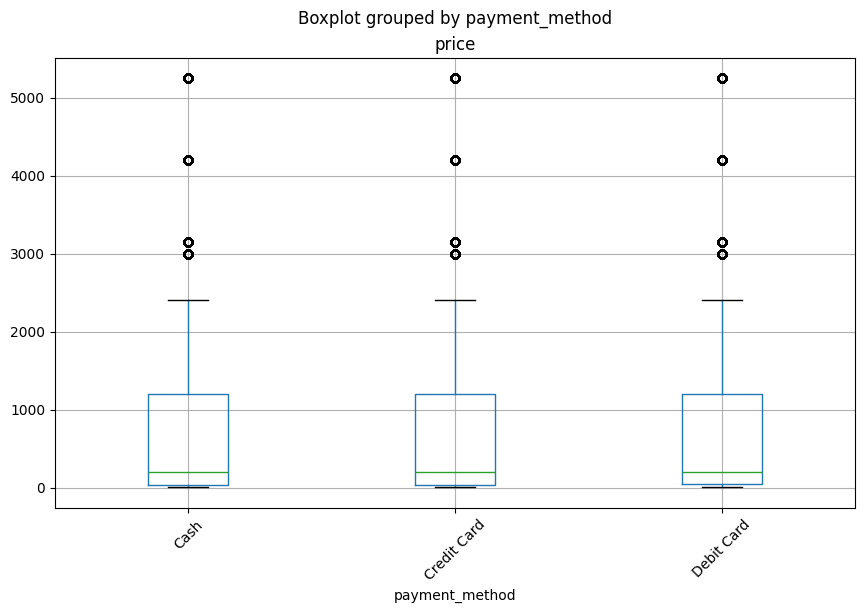

In [62]:
customers.boxplot(column="price", by="payment_method", figsize=(10,6), rot=45)

# date

In [67]:
customers["invoice_date"].head(10)


0      5/8/2022
1    12/12/2021
2     9/11/2021
3    16/05/2021
4    24/10/2021
5    24/05/2022
6    13/03/2022
7    13/01/2021
8     4/11/2021
9    22/08/2021
Name: invoice_date, dtype: object

In [ ]:
customers["invoice_date"] = pd.to_datetime(customers["invoice_date"], format="%d/%m/%Y")


In [ ]:
customers["invoice_date"].head(10)

0   2022-08-05
1   2021-12-12
2   2021-11-09
3   2021-05-16
4   2021-10-24
5   2022-05-24
6   2022-03-13
7   2021-01-13
8   2021-11-04
9   2021-08-22
Name: invoice_date, dtype: datetime64[ns]

In [74]:
customers["invoice_date"].min(), customers["invoice_date"].max()


(Timestamp('2021-01-01 00:00:00'), Timestamp('2023-03-08 00:00:00'))

In [75]:
(customers["invoice_date"].max() - customers["invoice_date"].min()).days

796

# mall

In [77]:
customers["shopping_mall"].value_counts()

shopping_mall
Mall of Istanbul     19943
Kanyon               19823
Metrocity            15011
Metropol AVM         10161
Istinye Park          9781
Zorlu Center          5075
Cevahir AVM           4991
Forum Istanbul        4947
Viaport Outlet        4914
Emaar Square Mall     4811
Name: count, dtype: int64

In [80]:
customers.groupby("shopping_mall")["category"].nunique()

shopping_mall
Cevahir AVM          8
Emaar Square Mall    8
Forum Istanbul       8
Istinye Park         8
Kanyon               8
Mall of Istanbul     8
Metrocity            8
Metropol AVM         8
Viaport Outlet       8
Zorlu Center         8
Name: category, dtype: int64